# Подготовка и объединение FPB + Food-101

Итог: обычный YOLO detection — `class_id x_center y_center width height`. Масса FPB отбрасывается при чтении и **не сохраняется ни в очищенных TXT, ни в итоговом manifest**. Для Food-101 по решению проекта используется рамка всего изображения: `0.5 0.5 1 1`.

Эта рамка является **условной разметкой**, а не измеренной границей еды. Итоговый mAP на смешанной выборке не заменяет оценку локализации на FPB. Для неё дополнительно создаётся `fpb_eval.yaml`.

In [1]:
from pathlib import Path
import os
import sys
import json

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts/dataset_pipeline.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Откройте ноутбук из папки проекта или notebooks/.")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(DATA / "cache/matplotlib"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts import dataset_pipeline as dp

cats = dp.catalogs(DATA)
display(pd.DataFrame([{"source": source, "classes": len(info["names"]), "revision": info["revision"]}
                      for source, info in cats.items()]))


,source,classes,revision
0,fpb,138,53fcacf4b9dbe24c1c6ffa5a2cdb9d8c502e482f
1,food101,101,83488de741c1bd1ce27aa6a2b33e19c7bdf92ca9


## 1. Настройки

`MODE="preview"` скачивает реальные примеры и проверяет весь путь склеивания. `MODE="full"` загружает все опубликованные FPB изображения и Food-101 Parquet (суммарно десятки ГБ с распакованными файлами/кешем). Рекомендуется не менее 35 ГБ свободного места. Повторный запуск использует уже загруженные файлы.

Оба режима сохраняют единственный результат в `data/processed/fpb_food101/`. Новая сборка заменяет предыдущую после успешной проверки; переключение с full на preview также заменит результат. Каталоги, индексы и список примеров сохраняются в `data/metadata/` и ускоряют повторный запуск после перезапуска ядра. `data/reports/` не создаётся.


In [2]:
MODE = "preview"  # Поменяйте на "full" для полной подготовки.
SEED = 42
FOOD101_VAL_FRACTION = 0.10
WORKERS = 8
SAMPLES_PER_CLASS = 3
MAX_SCAN = 1600

if MODE not in {"preview", "full"}:
    raise ValueError("MODE должен быть preview или full")
DECISIONS_PATH = DATA / "review/class_synonym_decisions.csv"
decisions = pd.read_csv(DECISIONS_PATH) if DECISIONS_PATH.exists() else dp.review_table(cats)
dp.validate_decisions(decisions, cats)
names, source_to_id, mapping_rows = dp.class_mapping(cats, decisions)
display(pd.DataFrame(mapping_rows).query("source == 'food101'"))
print("Классов:", len(names), "Режим:", MODE)

,source,source_class_id,source_class,class_id,class_name,rule
138,food101,0,apple_pie,138,apple_pie,food101_separate
139,food101,1,baby_back_ribs,139,baby_back_ribs,food101_separate
140,food101,2,baklava,93,pahlava,reviewed_alias
141,food101,3,beef_carpaccio,140,beef_carpaccio,food101_separate
142,food101,4,beef_tartare,141,beef_tartare,food101_separate
...,...,...,...,...,...,...
234,food101,96,tacos,220,tacos,food101_separate
235,food101,97,takoyaki,221,takoyaki,food101_separate
236,food101,98,tiramisu,127,tiramisu,exact_name
237,food101,99,tuna_tartare,222,tuna_tartare,food101_separate


Классов: 224 Режим: preview


## 2. Загрузка и чтение источников

FPB: авторские рамки, исходные классы, train/val сохраняются. Шестое поле исходного TXT игнорируется. Food-101: все классы, одна рамка всего кадра. В полной загрузке метка считывается из каждой строки Parquet.

Строгая проверка останавливает импорт при отсутствии train/val метки, неизвестном ID или некорректных координатах. Отсутствующая метка не превращается в пустой фон.


In [3]:
if MODE == "full":
    import shutil
    if shutil.disk_usage(DATA).free < 35 * 2**30:
        raise RuntimeError("Для полной загрузки освободите не менее 35 ГБ или начните с preview.")
    records = dp.prepare_full(DATA, cats, workers=WORKERS)
else:
    records, preview_coverage = dp.preview_samples(DATA, cats, per_class=SAMPLES_PER_CLASS,
                                                  max_scan=MAX_SCAN, workers=WORKERS)
    print("Неполное покрытие в preview:", preview_coverage["missing"])

display(pd.DataFrame(records).groupby(["source", "source_split"], dropna=False).size().rename("images").to_frame())
print("Все сырые изображения:", DATA / "raw")


Неполное покрытие в preview: ['icecream', 'pizza']


images
source  source_split        
food101 train             76
        validation         4
fpb     test               2
        train             44
        val                6

Все сырые изображения: c:\Users\Ilya\Магистратура уроки\Годовой проект - Дневник калорий\calorie_diary\data\raw


## 3. Объединение и защита разбиений

- FPB ID сохраняются; уникальные Food-101 классы добавляются в конец словаря. Подтверждённые синонимы получают ID класса FPB.
- Исходный Food-101 train делится по классам детерминированно на train/val. HF `validation` — оригинальный Food-101 test, он сохраняется как test.
- FPB test со скрытыми метками сохраняется отдельно как `fpb_test_unlabeled` и не включается в размеченные списки обучения/оценки.
- Пиксельные дубликаты удаляются с приоритетом holdout. Варианты одного исходного имени FPB не пересекают splits. Конфликтующая разметка одинакового фото исключается с записью причины.
- ID физических порций FPB в поставке не установлены: группировка имён и точных дубликатов не гарантирует устранение всех похожих ракурсов. Для научной оценки нужна дополнительная проверка таких групп.


In [4]:
OUTPUT, merged, summary = dp.build_dataset(DATA, cats, records, decisions, mode=MODE,
                                          val_fraction=FOOD101_VAL_FRACTION, seed=SEED)
print(json.dumps(summary, ensure_ascii=False, indent=2))
print("Результат:", OUTPUT.relative_to(ROOT))
display(merged.groupby(["source", "split", "box_origin"]).size().rename("images").to_frame())

{
  "mode": "preview",
  "classes": 224,
  "images": 132,
  "excluded": 0,
  "by_source_split": {
    "food101/train": 57,
    "food101/val": 19,
    "food101/test": 4,
    "fpb/fpb_test_unlabeled": 2,
    "fpb/train": 44,
    "fpb/val": 6
  },
  "unlabeled_fpb_test": 2,
  "portion_grouping": "Only filename variants and exact pixels; physical plate IDs are not provided.",
  "validation": {
    "checked_images": 132,
    "classes": 224,
    "status": "OK"
  }
}
Результат: data\processed\fpb_food101


images
source  split              box_origin              
food101 test               full_image_proxy       4
        train              full_image_proxy      57
        val                full_image_proxy      19
fpb     fpb_test_unlabeled native                 2
        train              native                44
        val                native                 6

## 4. Проверки сохранённых файлов

Проверяются открываемость фото, число полей YOLO, диапазоны координат и ID, совпадение TXT с manifest, отсутствие пересечений по точным пикселям/группам, полные рамки Food-101. При чтении допускается только численная погрешность границы до 1e-6: она приводится к краю кадра. Более существенный выход за границы останавливает импорт.


In [5]:
checks = dp.validate_export(OUTPUT)
display(checks)
config = dp.yaml.safe_load((OUTPUT / "data.yaml").read_text(encoding="utf-8"))
print((OUTPUT / "data.yaml").read_text(encoding="utf-8"))
excluded_path = OUTPUT / "excluded_records.json"
print("Исключения:", excluded_path if excluded_path.exists() else "нет")


{'checked_images': 132, 'classes': 224, 'status': 'OK'}

path: C:\Users\Ilya\Магистратура уроки\Годовой проект - Дневник калорий\calorie_diary\data\processed\fpb_food101
names:
- achichuk
- almond
- apple_juice
- apple_strudel
- balqaymaq
- bauyrsak
- beef
- beef_cutlet
- beefstroganov
- beet_salad
- belise_tea
- beshbarmak
- black_tea
- bliny
- borek
- borsh
- bread
- broccoli
- buckwheat
- bukteme
- bun
- burger
- butter
- caesar_salad
- capuccino
- cereal
- chak_chak
- cheburek
- cheese_sticks
- cheesecake
- chelpek
- chicken
- chicken_in_plum
- chocolate
- ciabatta
- coke
- compote
- cottage_cheese
- croissant
- cupcake
- dapanji
- doner
- dried_apricot
- dumpling_with_soup
- egg
- fanta
- fettucini
- fish_soup
- french_fries
- fresh_salad
- fried_aubergine
- fried_dumplings
- fried_lagman
- funchosa
- golubcy
- greek_salad
- green_tea
- grilled_vegetables
- honey
- hvorost
- icecream
- irimshik
- kazy
- kefir
- kespe
- ketchup
- khachapuri
- kirieshki_cheese
- kirieshki_shashlyk
- koktal
- korean_carrot
- kurt
- kuyrdak
- kymyz
- lemona

## 5. Визуальная проверка после записи

Следующие изображения читаются **из итоговой папки**, координаты и ID — **из записанных TXT**, подписи — из сохранённого `data.yaml`. Поэтому виден именно результат склеивания. Примеры отдельно показывают FPB, Food-101 и совпадающие итоговые классы обоих источников. Рисунки остаются в выводе ноутбука; файлы отчётов не создаются.


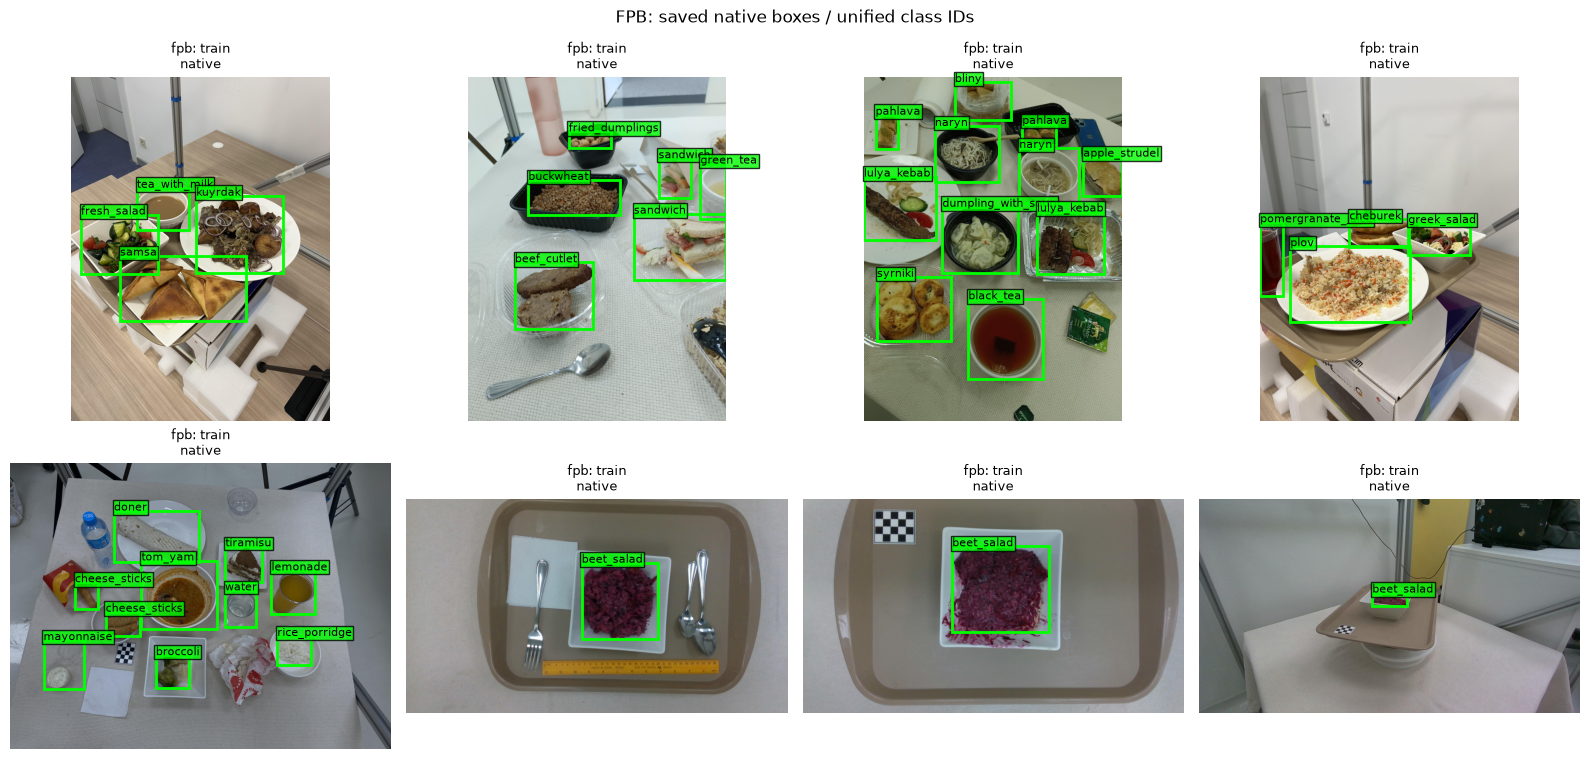

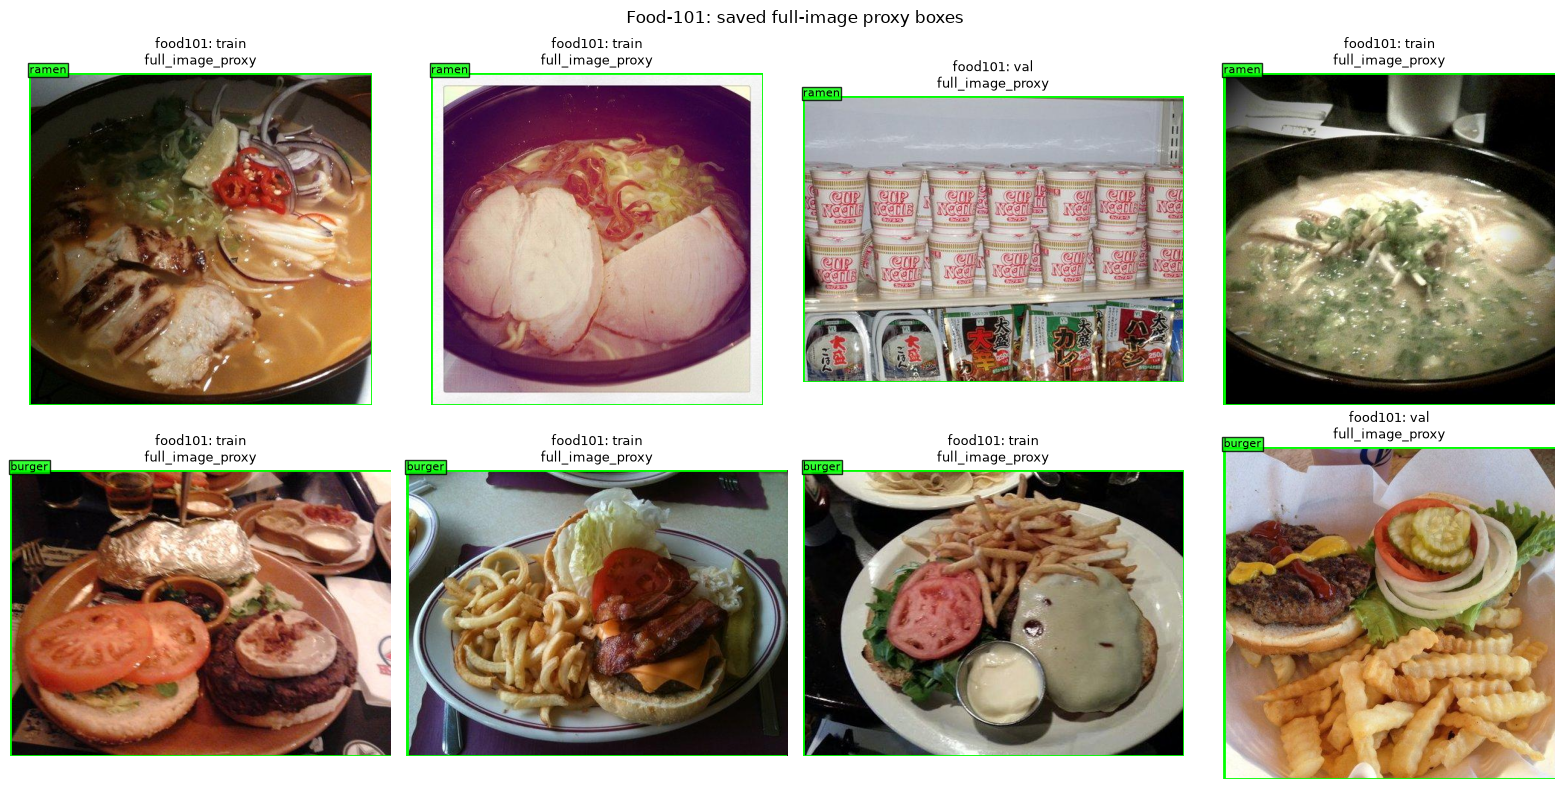

In [6]:
def show_saved(rows, title):
    visual = []
    for row in rows:
        row = dict(row)
        parsed = dp.parse_yolo((OUTPUT / row["label"]).read_text(encoding="utf-8"), len(config["names"]))
        row["objects"] = [{"class_id": obj["source_class_id"], "bbox": obj["bbox"]} for obj in parsed]
        visual.append(row)
    fig = dp.show_records(visual, config["names"], output_root=OUTPUT, count=8, title=title)
    if fig is not None:
        plt.close(fig)

labeled = merged[merged.label.notna()]
show_saved(labeled[labeled.source == "fpb"].head(8).to_dict("records"),
           "FPB: saved native boxes / unified class IDs")
show_saved(labeled[labeled.source == "food101"].head(8).to_dict("records"),
           "Food-101: saved full-image proxy boxes")


Общий ID 9 — beet_salad
Общий ID 21 — burger
Общий ID 23 — caesar_salad
Общий ID 29 — cheesecake


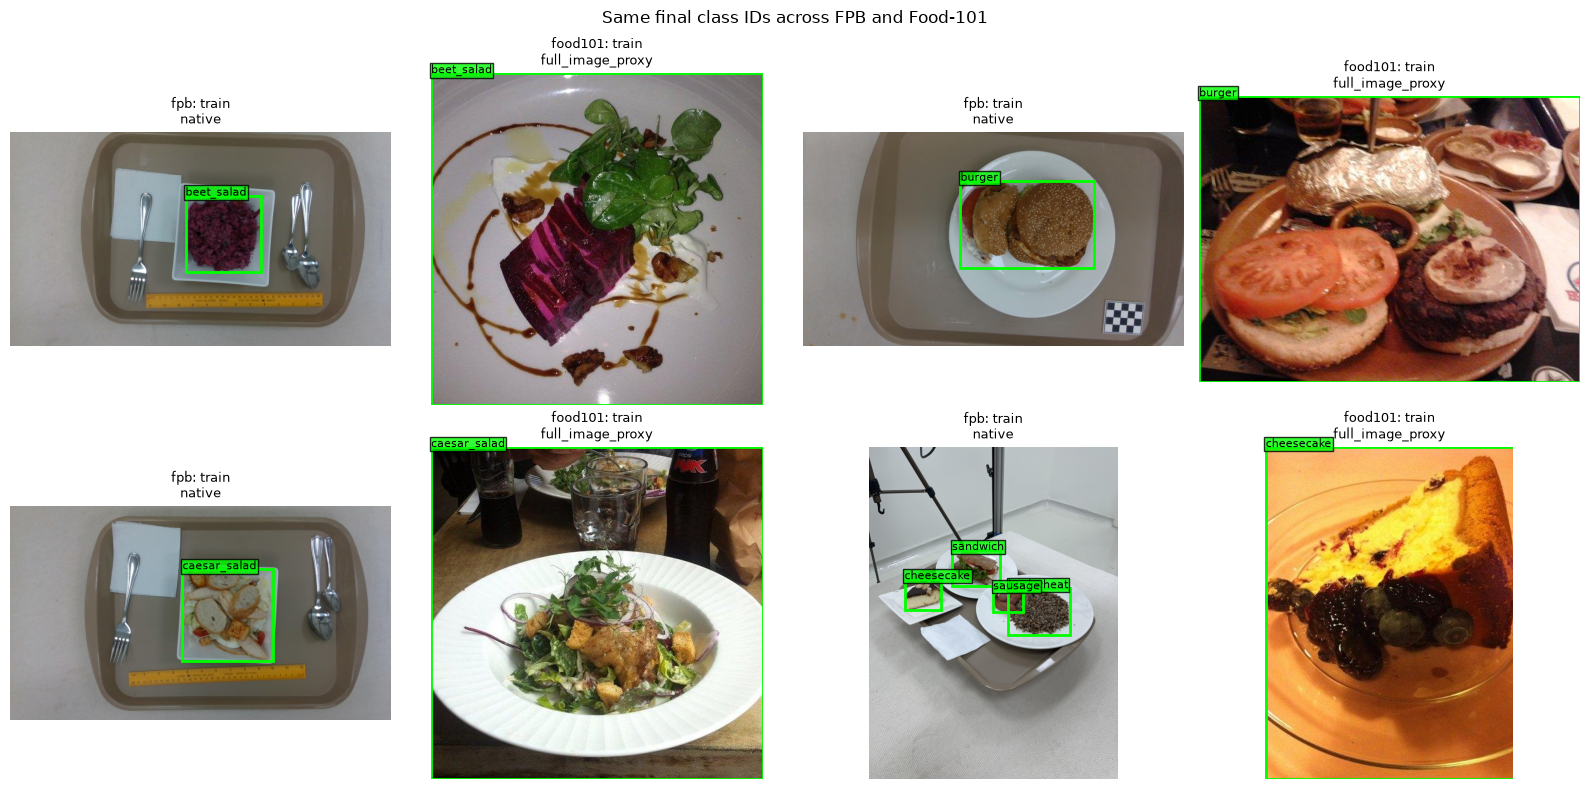

In [7]:
shared_gallery = []
for class_id in range(len(cats["fpb"]["names"])):
    matches = {}
    for row in labeled.to_dict("records"):
        if row["source"] not in matches and any(o["class_id"] == class_id for o in row["objects"]):
            matches[row["source"]] = row
    if set(matches) == {"fpb", "food101"}:
        print("Общий ID", class_id, "—", config["names"][class_id])
        shared_gallery.extend([matches["fpb"], matches["food101"]])
    if len(shared_gallery) >= 8:
        break
show_saved(shared_gallery, "Same final class IDs across FPB and Food-101")


## 6. Файлы для обучения и анализа

`data.yaml` — общий YOLO detection датасет; `fpb_eval.yaml` — оценка на FPB validation с настоящими рамками (если такие примеры есть). `class_mapping.csv` связывает исходные и итоговые ID. `manifest.jsonl` содержит источник, разбиение, исходный ID и происхождение рамки; массы там нет. `excluded_records.json` создаётся только при наличии исключённых записей и объясняет причины исключения. Единственный результат находится в `data/processed/fpb_food101/`. Версии источников хранятся в `data/metadata/sources.lock.json`, решения о синонимах — в `data/review/class_synonym_decisions.csv`; копий этих файлов в processed нет. Статистика сборки и результат проверки выводятся выше в ноутбуке, файл `build_complete.json` не создаётся.

Сборка сначала проверяется во временной папке, затем заменяет предыдущую целиком: старые изображения и метки не остаются. При ошибке подготовки предыдущий результат сохраняется. Временные файлы удаляются, старые папки `fpb_food101_preview_*` и `fpb_food101_full_*` удаляются после успешной сборки.

В preview словарь содержит все классы, но изображения покрывают только небольшой поднабор. Для обучения итогового бейзлайна переключите `MODE` на `full` и выполните ноутбук заново. Уникальные классы Food-101 при этом сохраняются полностью.

Увеличение числа классов — гипотеза о пользе для обобщения, её нужно проверить сравнением FPB-only и FPB+Food-101 на одной независимой выборке. Условные рамки могут ухудшать точность локализации; сравнивайте метрики по источникам отдельно.
